In [1]:
from pathlib import Path

import anndata as ad

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

interim_dir = project_root / "data" / "interim"
expression_path = interim_dir / "GSE176160_patients_normalized.h5ad"
clustered_path = interim_dir / "GSE176160_patients_clustered.h5ad"

adata = ad.read_h5ad(expression_path)
clustered_adata = ad.read_h5ad(clustered_path, backed="r")

try:
    assert adata.obs_names.is_unique, "Duplicate IDs in the expression file."
    assert clustered_adata.obs_names.is_unique, "Duplicate IDs in the clustering file."
    assert adata.obs_names.equals(clustered_adata.obs_names), "Cell IDs or order differ."

    cluster_labels = clustered_adata.obs["leiden_r05"].copy()
    assert cluster_labels.notna().all(), "Some cells lack a cluster label."
finally:
    clustered_adata.file.close()

adata.obs["leiden_r05"] = cluster_labels

print("Expression matrix:", adata.shape)
print("Reference clusters:", adata.obs["leiden_r05"].nunique())
print("Donors:", adata.obs["Donor"].nunique())

Expression matrix: (30589, 58735)
Reference clusters: 17
Donors: 12


In [2]:
import pandas as pd
import scanpy as sc

gene_screen_path = project_root / "results" / "tables" / "hvg_selection.csv"
gene_screen = pd.read_csv(gene_screen_path)

marker_gene_mask = adata.var_names.isin(gene_screen["gene"])
assert marker_gene_mask.sum() == len(gene_screen), "Gene identifiers do not match."

sc.tl.rank_genes_groups(
    adata,
    groupby="leiden_r05",
    reference="rest",
    method="t-test",
    use_raw=False,
    mask_var=marker_gene_mask,
    n_genes=30,
    pts=True,
    key_added="cluster_markers_r05",
)

print("Genes screened:", marker_gene_mask.sum())
print("Marker ranking complete.")

Genes screened: 32801
Marker ranking complete.


In [3]:
cluster_markers = sc.get.rank_genes_groups_df(
    adata,
    group=None,
    key="cluster_markers_r05",
).rename(columns={"group": "cluster", "names": "gene"})

top_markers_by_cluster = (
    cluster_markers.groupby("cluster", observed=True)
    .head(5)
    .groupby("cluster", observed=True)["gene"]
    .agg(", ".join)
    .rename("top_genes")
)

display(top_markers_by_cluster.to_frame())

,top_genes
cluster,
0,"SNHG5, COL3A1, RPLP1, LUM, AL365357.1"
1,"S100A11, LGALS1, COL1A2, COL3A1, CTHRC1"
10,"FGFBP3, CHCHD2, RPL39, RPS4X, TMSB4X"
11,"LGALS1, RPS18, RPL35, RPS2, RPL13A"
12,"GAPDH, RPL31, FABP7, RPS2, YBX1"
13,"RPL10P9, CHCHD2, NNAT, FABP7, RPS4Y1"
14,"AL450405.1, RPL10P9, ANXA2, ZNF667-AS1, MYL9"
15,"PLP1, SCRG1, CUEDC2, MPZ, SOX10"
16,"MLLT11, TAGLN3, MAP1B, BEX1, STMN2"


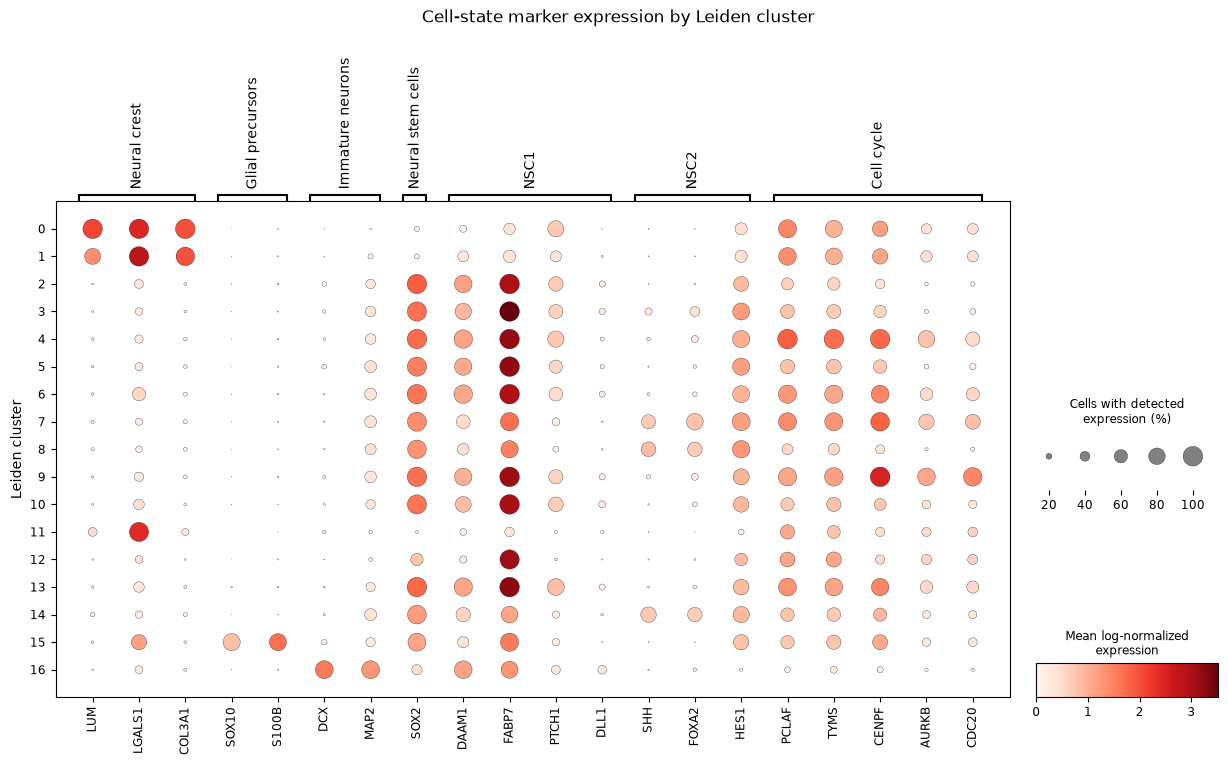

In [6]:
import matplotlib.pyplot as plt

marker_panel = {
    "Neural crest": ["LUM", "LGALS1", "COL3A1"],
    "Glial precursors": ["SOX10", "S100B"],
    "Immature neurons": ["DCX", "MAP2"],
    "Neural stem cells": ["SOX2"],
    "NSC1": ["DAAM1", "FABP7", "PTCH1", "DLL1"],
    "NSC2": ["SHH", "FOXA2", "HES1"],
    "Cell cycle": ["PCLAF", "TYMS", "CENPF", "AURKB", "CDC20"],
}

marker_dotplot = sc.pl.dotplot(
    adata,
    var_names=marker_panel,
    groupby="leiden_r05",
    categories_order=sorted(adata.obs["leiden_r05"].cat.categories, key=int),
    use_raw=False,
    figsize=(15, 8),
    return_fig=True,
)

marker_dotplot.legend(
    width=2.4,
    size_title="Cells with detected\nexpression (%)",
    colorbar_title="Mean log-normalized\nexpression",
)

main_ax = marker_dotplot.get_axes()["mainplot_ax"]
main_ax.set_ylabel("Leiden cluster")

marker_figure = main_ax.figure
marker_figure.subplots_adjust(top=0.73)
marker_figure.suptitle(
    "Cell-state marker expression by Leiden cluster",
    y=0.97,
)

plt.show()

In [7]:
nsc1_genes = marker_panel["NSC1"]
group_columns = ["leiden_r05", "Donor", "condition"]

nsc1_cells = sc.get.obs_df(
    adata,
    keys=[*group_columns, *nsc1_genes],
    use_raw=False,
)
nsc1_cells = nsc1_cells.loc[nsc1_cells["leiden_r05"].isin(["2", "5"])]

nsc1_detection = nsc1_cells[nsc1_genes].gt(0)
nsc1_detection[group_columns] = nsc1_cells[group_columns]

nsc1_by_donor = nsc1_detection.groupby(group_columns, observed=True)
nsc1_donor_summary = (
    nsc1_by_donor[nsc1_genes]
    .mean()
    .mul(100)
    .add_suffix("_pct_detected")
)
nsc1_donor_summary.insert(0, "n_cells", nsc1_by_donor.size())

display(nsc1_donor_summary.round(1))

n_cells  DAAM1_pct_detected  \
leiden_r05 Donor           condition                                
2          UKERiJ2C-R1-015 Parkinson        9                88.9   
           UKERiM89-R1-005 Parkinson       30                93.3   
           UKERiC99-R1-007 Parkinson       37                89.2   
           UKERiR66-R1-007 Parkinson      278                89.2   
           UKERiG3G-R1-039 Control          9                66.7   
           UKERi1E4-R1-003 Control         56                87.5   
           UKERiAY6-R1-003 Parkinson        7                57.1   
           UKERiPX7-R1-001 Parkinson       37                86.5   
           UKERi88H-R1-002 Parkinson      112                85.7   
           UKERiO3H-R1-005 Control       1547                85.9   
           UKERi82A-R1-002 Control          3               100.0   
5          UKERiJ2C-R1-015 Parkinson        4               100.0   
           UKERi1JF-R1-018 Control          1                 0.0   
           UKERiM89-R1-005 Parkinson      272                92.3   
           UKERiC99-R1-007 Parkinson       26                80.8   
           UKERiR66-R1-007 Parkinson      415                89.2   
           UKERiG3G-R1-039 Control         18                83.3   
           UKERi1E4-R1-003 Control         94                76.6   
           UKERiAY6-R1-003 Parkinson      216                86.1   
           UKERiPX7-R1-001 Parkinson       22                59.1   
           UKERi88H-R1-002 Parkinson      493                76.3   
           UKERiO3H-R1-005 Control         26                88.5   
           UKERi82A-R1-002 Control         76                94.7   

                                      FABP7_pct_detected  PTCH1_pct_detected  \
leiden_r05 Donor           condition                                           
2          UKERiJ2C-R1-015 Parkinson               100.0                88.9   
           UKERiM89-R1-005 Parkinson                96.7                60.0   
           UKERiC99-R1-007 Parkinson               100.0                94.6   
           UKERiR66-R1-007 Parkinson               100.0                76.6   
           UKERiG3G-R1-039 Control                 100.0                44.4   
           UKERi1E4-R1-003 Control                 100.0                62.5   
           UKERiAY6-R1-003 Parkinson               100.0                42.9   
           UKERiPX7-R1-001 Parkinson               100.0                67.6   
           UKERi88H-R1-002 Parkinson               100.0                60.7   
           UKERiO3H-R1-005 Control                  99.7                64.5   
           UKERi82A-R1-002 Control                 100.0                66.7   
5          UKERiJ2C-R1-015 Parkinson               100.0                50.0   
           UKERi1JF-R1-018 Control                 100.0               100.0   
           UKERiM89-R1-005 Parkinson               100.0                46.0   
           UKERiC99-R1-007 Parkinson               100.0                65.4   
           UKERiR66-R1-007 Parkinson               100.0                66.3   
           UKERiG3G-R1-039 Control                 100.0                44.4   
           UKERi1E4-R1-003 Control                 100.0                51.1   
           UKERiAY6-R1-003 Parkinson               100.0                62.0   
           UKERiPX7-R1-001 Parkinson               100.0                40.9   
           UKERi88H-R1-002 Parkinson               100.0                60.2   
           UKERiO3H-R1-005 Control                 100.0                57.7   
           UKERi82A-R1-002 Control                 100.0                57.9   

                                      DLL1_pct_detected  
leiden_r05 Donor           condition                     
2          UKERiJ2C-R1-015 Parkinson               11.1  
           UKERiM89-R1-005 Parkinson               56.7  
           UKERiC99-R1-007 Parkinson               67.6  
           UKERiR66-R

In [8]:
comparison_genes = ["PTCH1", "DLL1", *marker_panel["Cell cycle"]]
min_cells_per_cluster = 20

comparison_cells = sc.get.obs_df(
    adata,
    keys=[*group_columns, *comparison_genes],
    use_raw=False,
)
comparison_cells = comparison_cells.loc[
    comparison_cells["leiden_r05"].isin(["2", "5"])
]

detection = comparison_cells[comparison_genes].gt(0)
detection[group_columns] = comparison_cells[group_columns]

detection_pct = (
    detection.groupby(group_columns, observed=True)[comparison_genes]
    .mean()
    .mul(100)
)

eligible_groups = nsc1_donor_summary["n_cells"].ge(min_cells_per_cluster)
detection_pct = detection_pct.loc[eligible_groups]

donor_detection_difference = (
    detection_pct.loc["2"]
    .subtract(detection_pct.loc["5"])
    .dropna()
)

display(donor_detection_difference.round(1))

,,PTCH1,DLL1,PCLAF,TYMS,CENPF,AURKB,CDC20
Donor,condition,,,,,,,
UKERiM89-R1-005,Parkinson,14.0,33.5,2.2,-6.3,-19.3,-2.1,-1.7
UKERiC99-R1-007,Parkinson,29.2,40.6,-26.4,-19.9,-8.7,3.5,-18.8
UKERiR66-R1-007,Parkinson,10.4,8.7,-7.8,-11.3,-9.8,0.6,-11.4
UKERi1E4-R1-003,Control,11.4,11.9,-14.9,-14.8,-3.6,1.5,-2.0
UKERiPX7-R1-001,Parkinson,26.7,48.5,10.4,-9.6,-7.6,-10.1,-9.2
UKERi88H-R1-002,Parkinson,0.5,20.8,-1.7,-0.2,-6.3,-6.3,-2.9
UKERiO3H-R1-005,Control,6.8,10.1,14.3,-2.1,-17.0,-5.9,9.4


In [9]:
cycle_clusters = ["2", "5", "4", "9"]
cycle_genes = marker_panel["Cell cycle"]

cycle_cells = sc.get.obs_df(
    adata[adata.obs["leiden_r05"].isin(cycle_clusters)],
    keys=["leiden_r05", "Donor", *cycle_genes],
    use_raw=False,
)

cycle_detection = cycle_cells[cycle_genes].gt(0)
cycle_detection[["leiden_r05", "Donor"]] = cycle_cells[["leiden_r05", "Donor"]]

cycle_groups = cycle_detection.groupby(["Donor", "leiden_r05"], observed=True)
cycle_cell_counts = cycle_groups.size().unstack(fill_value=0)

shared_donors = cycle_cell_counts.index[
    cycle_cell_counts[cycle_clusters].ge(min_cells_per_cluster).all(axis=1)
]

cycle_detection_pct = cycle_groups[cycle_genes].mean().mul(100)
cycle_detection_pct = cycle_detection_pct.loc[
    cycle_detection_pct.index.get_level_values("Donor").isin(shared_donors)
]

cycle_summary = (
    cycle_detection_pct.groupby(level="leiden_r05", observed=True)
    .median()
    .reindex(cycle_clusters)
)

print("Donors with at least 20 cells in all four clusters:", len(shared_donors))
display(cycle_summary.round(1))

Donors with at least 20 cells in all four clusters: 7


,PCLAF,TYMS,CENPF,AURKB,CDC20
leiden_r05,,,,,
2,53.3,54.1,37.8,9.4,13.5
5,61.5,63.6,50.0,15.2,19.9
4,99.5,99.2,98.9,80.1,63.0
9,93.7,92.8,100.0,92.7,95.8


In [10]:
nsc2_clusters = ["7", "8"]
nsc2_genes = ["SOX2", *marker_panel["NSC2"], *marker_panel["Cell cycle"]]
nsc2_group_columns = ["Donor", "leiden_r05"]

nsc2_cells = sc.get.obs_df(
    adata[adata.obs["leiden_r05"].isin(nsc2_clusters)],
    keys=[*nsc2_group_columns, *nsc2_genes],
    use_raw=False,
)

nsc2_detection = nsc2_cells[nsc2_genes].gt(0)
nsc2_detection[nsc2_group_columns] = nsc2_cells[nsc2_group_columns]

nsc2_groups = nsc2_detection.groupby(nsc2_group_columns, observed=True)
nsc2_cell_counts = nsc2_groups.size().unstack(fill_value=0)

nsc2_shared_donors = nsc2_cell_counts.index[
    nsc2_cell_counts[nsc2_clusters].ge(min_cells_per_cluster).all(axis=1)
]

nsc2_detection_pct = nsc2_groups[nsc2_genes].mean().mul(100)
nsc2_shared_detection = nsc2_detection_pct.loc[
    nsc2_detection_pct.index.get_level_values("Donor").isin(nsc2_shared_donors)
]

nsc2_summary = (
    nsc2_shared_detection.groupby(level="leiden_r05", observed=True)
    .median()
    .reindex(nsc2_clusters)
)

print("Donors with at least 20 cells in both clusters:", len(nsc2_shared_donors))
display(nsc2_summary.round(1))

Donors with at least 20 cells in both clusters: 9


,SOX2,SHH,FOXA2,HES1,PCLAF,TYMS,CENPF,AURKB,CDC20
leiden_r05,,,,,,,,,
7,97.0,74.6,79.8,89.7,92.6,92.1,98.6,80.9,75.0
8,93.8,81.7,63.8,87.0,49.1,53.1,39.7,9.5,11.6


In [11]:
cluster_7_detection = nsc2_shared_detection.xs("7", level="leiden_r05")
cluster_8_detection = nsc2_shared_detection.xs("8", level="leiden_r05")

nsc2_donor_difference = cluster_7_detection.subtract(cluster_8_detection)

assert len(nsc2_donor_difference) == len(nsc2_shared_donors)
assert nsc2_donor_difference.notna().all().all(), "Unmatched donor rows."

nsc2_direction_summary = pd.DataFrame({
    "n_donors_higher_in_7": nsc2_donor_difference.gt(0).sum(),
    "n_donors_higher_in_8": nsc2_donor_difference.lt(0).sum(),
    "median_difference_pp": nsc2_donor_difference.median(),
})

display(nsc2_direction_summary.round(1))

,n_donors_higher_in_7,n_donors_higher_in_8,median_difference_pp
SOX2,8,1,2.4
SHH,1,8,-4.0
FOXA2,9,0,16.2
HES1,7,2,4.9
PCLAF,9,0,44.2
TYMS,9,0,39.0
CENPF,9,0,60.3
AURKB,9,0,72.3
CDC20,9,0,64.7


In [12]:
comparison_clusters = ["7", "8", "14"]
comparison_genes = ["SOX2", "SHH", "FOXA2", "HES1", "AURKB", "CDC20"]

cluster_14_donors = adata.obs.loc[adata.obs["leiden_r05"].eq("14"), "Donor"]
cluster_14_top_donor = cluster_14_donors.value_counts().idxmax()

comparison_mask = (
    adata.obs["Donor"].eq(cluster_14_top_donor)
    & adata.obs["leiden_r05"].isin(comparison_clusters)
)

comparison_cells = sc.get.obs_df(
    adata[comparison_mask],
    keys=["leiden_r05", *comparison_genes],
    use_raw=False,
)

marker_detection = comparison_cells[comparison_genes].gt(0)
marker_groups = marker_detection.groupby(
    comparison_cells["leiden_r05"],
    observed=True,
)

cluster_14_comparison = (
    marker_groups.mean()
    .mul(100)
    .add_suffix("_pct_detected")
    .reindex(comparison_clusters)
)
cluster_14_comparison.insert(
    0, "n_cells", marker_groups.size().reindex(comparison_clusters, fill_value=0)
)

print("Dominant donor in cluster 14:", cluster_14_top_donor)
display(cluster_14_comparison.round(1))

Dominant donor in cluster 14: UKERi1JF-R1-018


,n_cells,SOX2_pct_detected,SHH_pct_detected,FOXA2_pct_detected,HES1_pct_detected,AURKB_pct_detected,CDC20_pct_detected
leiden_r05,,,,,,,
7,2,100.0,50.0,100.0,100.0,100.0,100.0
8,2,100.0,0.0,50.0,100.0,0.0,0.0
14,1306,94.2,73.2,67.1,77.9,30.5,31.2


In [13]:
cycling_nsc_clusters = ["2", "4", "9"]
identity_genes = ["SOX2", *marker_panel["NSC1"], *marker_panel["NSC2"]]
identity_group_columns = ["Donor", "leiden_r05"]

identity_mask = (
    adata.obs["Donor"].isin(shared_donors)
    & adata.obs["leiden_r05"].isin(cycling_nsc_clusters)
)

identity_cells = sc.get.obs_df(
    adata[identity_mask],
    keys=[*identity_group_columns, *identity_genes],
    use_raw=False,
)

identity_detection = identity_cells[identity_genes].gt(0)
identity_detection[identity_group_columns] = identity_cells[identity_group_columns]

cycling_nsc_detection_by_donor = (
    identity_detection.groupby(identity_group_columns, observed=True)[identity_genes]
    .mean()
    .mul(100)
)

cycling_nsc_marker_summary = (
    cycling_nsc_detection_by_donor.groupby(level="leiden_r05", observed=True)
    .median()
    .reindex(cycling_nsc_clusters)
)

display(cycling_nsc_marker_summary.round(1))

,SOX2,DAAM1,FABP7,PTCH1,DLL1,SHH,FOXA2,HES1
leiden_r05,,,,,,,,
2,98.5,87.5,100.0,64.5,32.1,2.2,6.7,65.2
4,98.8,93.2,100.0,77.4,11.8,4.1,22.0,86.2
9,99.4,88.4,100.0,65.1,21.6,7.2,20.9,79.6


In [14]:
identity_check_genes = ["PTCH1", "DLL1", "FOXA2"]
cycle_check_genes = ["CENPF", "AURKB", "CDC20"]

cycling_marker_detection = cycling_nsc_detection_by_donor[
    identity_check_genes
].join(cycle_detection_pct[cycle_check_genes])

assert cycling_marker_detection.notna().all().all(), "Unmatched marker rows."

reference_detection = cycling_marker_detection.xs("2", level="leiden_r05")
comparison_summaries = {}

for cluster_id in ["4", "9"]:
    cluster_detection = cycling_marker_detection.xs(cluster_id, level="leiden_r05")
    donor_difference = cluster_detection.subtract(reference_detection)

    assert len(donor_difference) == len(shared_donors)
    assert donor_difference.notna().all().all(), "Unmatched donor rows."

    comparison_summaries[cluster_id] = pd.DataFrame({
        "n_donors_higher": donor_difference.gt(0).sum(),
        "n_donors_lower": donor_difference.lt(0).sum(),
        "median_difference_pp": donor_difference.median(),
    })

cycling_nsc_direction_summary = pd.concat(
    comparison_summaries,
    names=["cluster", "gene"],
)

display(cycling_nsc_direction_summary.round(1))

n_donors_higher  n_donors_lower  median_difference_pp
cluster gene                                                        
4       PTCH1                6               1                   8.8
        DLL1                 0               7                 -25.4
        FOXA2                6               1                   9.7
        CENPF                7               0                  57.8
        AURKB                7               0                  64.5
        CDC20                7               0                  48.2
9       PTCH1                3               4                  -1.8
        DLL1                 1               6                 -18.2
        FOXA2                7               0                  10.2
        CENPF                7               0                  62.2
        AURKB                7               0                  83.7
        CDC20                7               0                  81.5

In [15]:
identity_check_genes = ["PTCH1", "DLL1", "FOXA2"]
cycle_check_genes = ["CENPF", "AURKB", "CDC20"]

cycling_marker_detection = cycling_nsc_detection_by_donor[
    identity_check_genes
].join(cycle_detection_pct[cycle_check_genes])

assert cycling_marker_detection.notna().all().all(), "Unmatched marker rows."

reference_detection = cycling_marker_detection.xs("2", level="leiden_r05")
comparison_summaries = {}

for cluster_id in ["4", "9"]:
    cluster_detection = cycling_marker_detection.xs(cluster_id, level="leiden_r05")
    donor_difference = cluster_detection.subtract(reference_detection)

    assert len(donor_difference) == len(shared_donors)
    assert donor_difference.notna().all().all(), "Unmatched donor rows."

    comparison_summaries[cluster_id] = pd.DataFrame({
        "n_donors_higher": donor_difference.gt(0).sum(),
        "n_donors_lower": donor_difference.lt(0).sum(),
        "median_difference_pp": donor_difference.median(),
    })

cycling_nsc_direction_summary = pd.concat(
    comparison_summaries,
    names=["cluster", "gene"],
)

display(cycling_nsc_direction_summary.round(1))

n_donors_higher  n_donors_lower  median_difference_pp
cluster gene                                                        
4       PTCH1                6               1                   8.8
        DLL1                 0               7                 -25.4
        FOXA2                6               1                   9.7
        CENPF                7               0                  57.8
        AURKB                7               0                  64.5
        CDC20                7               0                  48.2
9       PTCH1                3               4                  -1.8
        DLL1                 1               6                 -18.2
        FOXA2                7               0                  10.2
        CENPF                7               0                  62.2
        AURKB                7               0                  83.7
        CDC20                7               0                  81.5

In [16]:
lineage_clusters = ["0", "1", "11", "15", "16"]
lineage_genes = [
    *marker_panel["Neural crest"],
    *marker_panel["Glial precursors"],
    *marker_panel["Immature neurons"],
]

lineage_cells = sc.get.obs_df(
    adata[adata.obs["leiden_r05"].isin(lineage_clusters)],
    keys=["leiden_r05", "Donor", *lineage_genes],
    use_raw=False,
)

lineage_detection = lineage_cells[lineage_genes].gt(0)
lineage_groups = lineage_detection.groupby(
    [lineage_cells["leiden_r05"], lineage_cells["Donor"]],
    observed=True,
)

lineage_cells_per_donor = lineage_groups.size()
lineage_detection_pct = lineage_groups.mean().mul(100)
eligible_lineage_detection = lineage_detection_pct.loc[
    lineage_cells_per_donor.ge(min_cells_per_cluster)
]

lineage_by_cluster = eligible_lineage_detection.groupby(
    level="leiden_r05",
    observed=True,
)
lineage_marker_summary = lineage_by_cluster.median().reindex(lineage_clusters)
lineage_marker_summary.insert(
    0,
    "n_donors_ge_20_cells",
    lineage_by_cluster.size().reindex(lineage_clusters, fill_value=0),
)

display(lineage_marker_summary.round(1))

,n_donors_ge_20_cells,LUM,LGALS1,COL3A1,SOX10,S100B,DCX,MAP2
leiden_r05,,,,,,,,
0,2,97.0,99.2,99.7,0.2,1.0,0.5,2.7
1,9,89.7,98.2,96.9,0.5,2.7,1.2,11.1
11,5,40.0,96.0,16.5,0.0,0.0,10.6,3.9
15,8,6.5,69.9,7.1,85.6,83.0,17.0,36.8
16,9,3.6,27.1,7.8,1.0,2.9,89.6,88.2


In [17]:
candidate_clusters = ["3", "6", "10", "12", "13"]
candidate_genes = [
    "SOX2",
    *marker_panel["NSC1"],
    "SHH", "FOXA2",
    "CENPF", "AURKB",
]

candidate_cells = sc.get.obs_df(
    adata[adata.obs["leiden_r05"].isin(candidate_clusters)],
    keys=["leiden_r05", "Donor", *candidate_genes],
    use_raw=False,
)

candidate_groups = candidate_cells[candidate_genes].gt(0).groupby(
    [candidate_cells["leiden_r05"], candidate_cells["Donor"]],
    observed=True,
)

candidate_cell_counts = candidate_groups.size()
candidate_detection_pct = candidate_groups.mean().mul(100)

eligible_candidate_detection = candidate_detection_pct.loc[
    candidate_cell_counts.ge(min_cells_per_cluster)
]

candidate_by_cluster = eligible_candidate_detection.groupby(
    level="leiden_r05",
    observed=True,
)
candidate_marker_summary = candidate_by_cluster.median().reindex(candidate_clusters)
candidate_marker_summary.insert(
    0,
    "n_donors_ge_20_cells",
    candidate_by_cluster.size().reindex(candidate_clusters, fill_value=0),
)

display(candidate_marker_summary.round(1))

,n_donors_ge_20_cells,SOX2,DAAM1,FABP7,PTCH1,DLL1,SHH,FOXA2,CENPF,AURKB
leiden_r05,,,,,,,,,,
3,4,98.3,76.4,100.0,63.4,21.7,29.8,37.4,58.5,13.8
6,4,95.4,91.5,99.9,59.5,16.2,4.7,11.2,85.9,61.2
10,1,96.9,74.9,99.6,68.9,25.0,2.6,15.5,51.6,34.2
12,11,48.6,26.8,98.3,7.3,2.2,3.7,4.7,36.6,43.9
13,1,98.8,91.1,99.9,80.7,21.5,4.6,11.3,85.4,55.8


In [18]:
cluster_6_comparison = ["2", "4", "6", "9"]
cluster_6_cycle_genes = ["CENPF", "AURKB", "CDC20"]

cluster_6_cells = sc.get.obs_df(
    adata[adata.obs["leiden_r05"].isin(cluster_6_comparison)],
    keys=["Donor", "leiden_r05", *cluster_6_cycle_genes],
    use_raw=False,
)

cluster_6_groups = cluster_6_cells[cluster_6_cycle_genes].gt(0).groupby(
    [cluster_6_cells["Donor"], cluster_6_cells["leiden_r05"]],
    observed=True,
)

cluster_6_counts = cluster_6_groups.size()
cluster_6_counts_wide = cluster_6_counts.unstack(fill_value=0)
cluster_6_shared_donors = cluster_6_counts_wide.index[
    cluster_6_counts_wide[cluster_6_comparison]
    .ge(min_cells_per_cluster)
    .all(axis=1)
]

cluster_6_cycle_summary = cluster_6_groups.mean().mul(100)
cluster_6_cycle_summary.insert(0, "n_cells", cluster_6_counts)

display(
    cluster_6_cycle_summary.loc[
        cluster_6_cycle_summary.index.get_level_values("Donor").isin(
            cluster_6_shared_donors
        )
    ].round(1)
)

n_cells  CENPF  AURKB  CDC20
Donor           leiden_r05                              
UKERiC99-R1-007 2                37   29.7   18.9    8.1
                4               879   99.2   83.4   70.8
                6                28   92.9   78.6   64.3
                9               827   99.6   84.6   91.1
UKERiR66-R1-007 2               278   61.5   15.8   17.3
                4               376   98.9   77.1   65.4
                6                36   83.3   66.7   55.6
                9               333   99.7   91.3   95.8

In [19]:
cluster_3_comparison = ["2", "3", "8"]
cluster_3_genes = ["DAAM1", "PTCH1", "DLL1", "SHH", "FOXA2", "HES1"]

cluster_3_cells = sc.get.obs_df(
    adata[adata.obs["leiden_r05"].isin(cluster_3_comparison)],
    keys=["Donor", "leiden_r05", *cluster_3_genes],
    use_raw=False,
)

cluster_3_groups = cluster_3_cells[cluster_3_genes].gt(0).groupby(
    [cluster_3_cells["Donor"], cluster_3_cells["leiden_r05"]],
    observed=True,
)

cluster_3_counts = cluster_3_groups.size()
cluster_3_counts_wide = cluster_3_counts.unstack(fill_value=0)
cluster_3_shared_donors = cluster_3_counts_wide.index[
    cluster_3_counts_wide[cluster_3_comparison]
    .ge(min_cells_per_cluster)
    .all(axis=1)
]

cluster_3_marker_summary = cluster_3_groups.mean().mul(100)
cluster_3_marker_summary.insert(0, "n_cells", cluster_3_counts)

display(
    cluster_3_marker_summary.loc[
        cluster_3_marker_summary.index.get_level_values("Donor").isin(
            cluster_3_shared_donors
        )
    ].round(1)
)

n_cells  DAAM1  PTCH1  DLL1   SHH  FOXA2  HES1
Donor           leiden_r05                                                
UKERiM89-R1-005 2                30   93.3   60.0  56.7   0.0    6.7  60.0
                3                54   75.9   61.1  22.2  33.3   35.2  79.6
                8               269   54.3   15.6   2.6  87.4   58.0  87.0
UKERiC99-R1-007 2                37   89.2   94.6  67.6   2.7    2.7  24.3
                3              1963   79.6   65.7  21.2  26.2   39.6  83.3
                8                64   48.4    9.4   1.6  87.5   75.0  89.1
UKERiR66-R1-007 2               278   89.2   76.6  21.9   2.2    1.4  62.6
                3                65   76.9   66.2  10.8  13.8   27.7  80.0
                8               116   48.3   23.3   3.4  67.2   63.8  80.2

In [20]:
co_detection_cells = cluster_3_cells.loc[
    cluster_3_cells["Donor"].isin(cluster_3_shared_donors)
]

ptch1_detected = co_detection_cells["PTCH1"].gt(0)
foxa2_detected = co_detection_cells["FOXA2"].gt(0)

co_detection = pd.DataFrame({
    "PTCH1_only": ptch1_detected & ~foxa2_detected,
    "FOXA2_only": ~ptch1_detected & foxa2_detected,
    "both_detected": ptch1_detected & foxa2_detected,
    "neither_detected": ~ptch1_detected & ~foxa2_detected,
})

co_detection_groups = co_detection.groupby(
    [co_detection_cells["Donor"], co_detection_cells["leiden_r05"]],
    observed=True,
)

cluster_3_co_detection_summary = (
    co_detection_groups.mean().mul(100).add_suffix("_pct")
)
cluster_3_co_detection_summary.insert(0, "n_cells", co_detection_groups.size())

display(cluster_3_co_detection_summary.round(1))

n_cells  PTCH1_only_pct  FOXA2_only_pct  \
Donor           leiden_r05                                            
UKERiM89-R1-005 2                30            56.7             3.3   
                3                54            40.7            14.8   
                8               269             6.3            48.7   
UKERiC99-R1-007 2                37            91.9             0.0   
                3              1963            42.0            15.9   
                8                64             3.1            68.8   
UKERiR66-R1-007 2               278            75.2             0.0   
                3                65            50.8            12.3   
                8               116             6.0            46.6   

                            both_detected_pct  neither_detected_pct  
Donor           leiden_r05                                           
UKERiM89-R1-005 2                         3.3                  36.7  
                3                        20.4                  24.1  
                8                         9.3                  35.7  
UKERiC99-R1-007 2                         2.7                   5.4  
                3                        23.7                  18.4  
                8                         6.2                  21.9  
UKERiR66-R1-007 2                         1.4                  23.4  
                3                        15.4                  21.5  
                8                        17.2                  30.2

In [21]:
provisional_cell_states = {
    "0": "Neural crest-like",
    "1": "Neural crest-like",
    "2": "NSC1-like",
    "3": "NSC-like (mixed marker profile)",
    "4": "Cycling NSC1-like",
    "5": "NSC1-like",
    "6": "Cycling NSC1-like",
    "7": "Cycling NSC2-like",
    "8": "NSC2-like",
    "9": "Cycling NSC1-like",
    "10": "NSC1-like",
    "11": "Unresolved",
    "12": "Unresolved",
    "13": "Cycling NSC1-like",
    "14": "NSC2-like",
    "15": "Glial precursor-like",
    "16": "Immature neuron-like",
}

annotation_donor_counts = pd.crosstab(
    adata.obs["leiden_r05"],
    adata.obs["Donor"],
)

assert set(annotation_donor_counts.index) == set(provisional_cell_states), (
    "Provisional labels must cover every reference cluster."
)

cluster_annotation_review = annotation_donor_counts.sum(axis=1).to_frame("n_cells")
cluster_annotation_review.insert(
    0, "provisional_cell_state",
    cluster_annotation_review.index.map(provisional_cell_states),
)
cluster_annotation_review["n_donors_ge_20_cells"] = (
    annotation_donor_counts.ge(min_cells_per_cluster).sum(axis=1)
)
cluster_annotation_review["top_donor_pct"] = (
    annotation_donor_counts.max(axis=1)
    .div(cluster_annotation_review["n_cells"])
    .mul(100)
)

display(
    cluster_annotation_review.reindex(list(provisional_cell_states))
    .round({"top_donor_pct": 1})
)

,provisional_cell_state,n_cells,n_donors_ge_20_cells,top_donor_pct
leiden_r05,,,,
0,Neural crest-like,2393,2,97.2
1,Neural crest-like,2498,9,26.3
2,NSC1-like,2125,7,72.8
3,NSC-like (mixed marker profile),2173,4,90.3
4,Cycling NSC1-like,2171,8,40.5
5,NSC1-like,1663,9,29.6
6,Cycling NSC1-like,1438,4,90.3
7,Cycling NSC2-like,1681,10,30.3
8,NSC2-like,3520,10,38.5


In [22]:
cell_state_labels = (
    adata.obs["leiden_r05"]
    .astype("string")
    .map(provisional_cell_states)
)

assert cell_state_labels.notna().all(), "Some cells lack a provisional label."

adata.obs["provisional_cell_state"] = pd.Categorical(cell_state_labels)

state_donor_counts = pd.crosstab(
    adata.obs["provisional_cell_state"],
    [adata.obs["condition"], adata.obs["Donor"]],
)

state_donor_coverage = state_donor_counts.sum(axis=1).to_frame("n_cells")

for condition in ["Control", "Parkinson"]:
    condition_counts = state_donor_counts.xs(
        condition,
        axis=1,
        level="condition",
    )
    column_prefix = condition.lower()

    state_donor_coverage[f"{column_prefix}_n_cells"] = condition_counts.sum(axis=1)
    state_donor_coverage[f"{column_prefix}_n_donors_ge_20"] = (
        condition_counts.ge(min_cells_per_cluster).sum(axis=1)
    )

assert state_donor_coverage["n_cells"].sum() == adata.n_obs

display(state_donor_coverage.sort_values("n_cells", ascending=False))

,n_cells,control_n_cells,control_n_donors_ge_20,parkinson_n_cells,parkinson_n_donors_ge_20
provisional_cell_state,,,,,
Cycling NSC1-like,7085,971,4,6114,7
NSC1-like,6595,4612,4,1983,6
Neural crest-like,4891,2754,2,2137,7
NSC2-like,4846,2259,5,2587,6
NSC-like (mixed marker profile),2173,35,0,2138,4
Unresolved,1797,540,5,1257,7
Cycling NSC2-like,1681,260,3,1421,7
Glial precursor-like,956,139,2,817,6
Immature neuron-like,565,110,3,455,6


In [23]:
nsc1_state_cells = adata.obs.loc[
    adata.obs["provisional_cell_state"].eq("NSC1-like")
]
donor_group_columns = ["condition", "Donor"]

nsc1_all_counts = (
    nsc1_state_cells.groupby(donor_group_columns, observed=True).size()
)

nsc1_without_cluster_10_counts = (
    nsc1_state_cells.loc[nsc1_state_cells["leiden_r05"].ne("10")]
    .groupby(donor_group_columns, observed=True)
    .size()
    .reindex(nsc1_all_counts.index, fill_value=0)
)

nsc1_coverage_sensitivity = pd.DataFrame({
    "all_nsc1_like": nsc1_all_counts,
    "without_cluster_10": nsc1_without_cluster_10_counts,
})

display(nsc1_coverage_sensitivity)

display(
    nsc1_coverage_sensitivity.ge(min_cells_per_cluster)
    .groupby(level="condition", observed=True)
    .sum()
)

all_nsc1_like  without_cluster_10
condition Donor                                             
Control   UKERi1JF-R1-018              6                   1
          UKERiG3G-R1-039           2792                  27
          UKERi1E4-R1-003            151                 150
          UKERiO3H-R1-005           1583                1573
          UKERi82A-R1-002             80                  79
Parkinson UKERiJ2C-R1-015             13                  13
          UKERiM89-R1-005            302                 302
          UKERiC99-R1-007             66                  63
          UKERiR66-R1-007            695                 693
          UKERiAY6-R1-003            226                 223
          UKERiPX7-R1-001             60                  59
          UKERi88H-R1-002            621                 605

,all_nsc1_like,without_cluster_10
condition,,
Control,4,4
Parkinson,6,6


In [24]:
tables_dir = project_root / "results" / "tables"
figures_dir = project_root / "results" / "figures"

tables_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

cluster_markers.to_csv(
    tables_dir / "cluster_marker_candidates_r05.csv",
    index=False,
)
cluster_annotation_review.reindex(list(provisional_cell_states)).to_csv(
    tables_dir / "cluster_annotation_review_r05.csv",
)
state_donor_counts.T.to_csv(
    tables_dir / "cell_state_counts_by_donor.csv",
)
state_donor_coverage.sort_values("n_cells", ascending=False).to_csv(
    tables_dir / "cell_state_donor_coverage.csv",
)
nsc1_coverage_sensitivity.to_csv(
    tables_dir / "nsc1_like_coverage_sensitivity.csv",
)

for extension in ("png", "pdf"):
    figure_path = figures_dir / f"cell_state_markers_by_cluster.{extension}"
    marker_figure.savefig(figure_path, dpi=300, bbox_inches="tight")
    print("Saved figure:", figure_path.name)

print("Annotation tables saved to:", tables_dir)

Saved figure: cell_state_markers_by_cluster.png
Saved figure: cell_state_markers_by_cluster.pdf
Annotation tables saved to: /Volumes/Amin's SSD/PhD_Projects/pd-nsc-scrna/results/tables


In [25]:
clustered_adata = ad.read_h5ad(clustered_path, backed="r")

try:
    assert clustered_adata.obs_names.equals(adata.obs_names), (
        "Cell IDs or order differ between the expression and clustering files."
    )

    umap_coordinates = clustered_adata.obsm["X_umap"].copy()
finally:
    clustered_adata.file.close()

assert umap_coordinates.shape == (adata.n_obs, 2)
assert adata.obs["provisional_cell_state"].notna().all()

adata.obsm["X_umap"] = umap_coordinates

annotated_path = interim_dir / "GSE176160_patients_annotated.h5ad"
adata.write_h5ad(annotated_path, compression="gzip")

print("Saved annotated dataset:", annotated_path.name)

Saved annotated dataset: GSE176160_patients_annotated.h5ad


In [26]:
import numpy as np

saved_adata = ad.read_h5ad(annotated_path, backed="r")

try:
    assert saved_adata.shape == adata.shape
    assert saved_adata.obs_names.equals(adata.obs_names)
    assert saved_adata.obs["provisional_cell_state"].equals(
        adata.obs["provisional_cell_state"]
    )
    np.testing.assert_array_equal(saved_adata.obsm["X_umap"], umap_coordinates)

    print("Verified expression shape:", saved_adata.shape)
    print("Verified UMAP shape:", saved_adata.obsm["X_umap"].shape)
    print("Provisional labels:", saved_adata.obs["provisional_cell_state"].nunique())
finally:
    saved_adata.file.close()

Verified expression shape: (30589, 58735)
Verified UMAP shape: (30589, 2)
Provisional labels: 9
